# Iapetus

Last updated: 2026-11-25

In [1]:
# Iapetus debris ring simulation
# Sun + Saturn + Iapetus + 100 debris particles
# This version tests Ph4 collision detection. The debris ring itself is not yet evolving inward.

import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches

from amuse.units import units, constants, nbody_system
from amuse.datamodel import Particles
from amuse.community.ph4.interface import Ph4
from amuse.plot import scatter, UnitlessArgs

## Initial Conditions

### Making System

In [36]:
#INIT PARAM
#Source: Our original Iapetus code, with physical parameters consistent with Stickle & Roberts (2018)

N = 100000

#Fixed random seed so we generate the same debris positions every time we run the simulation
rng = np.random.default_rng(42)

#Masses of the 3 main gravitational bodies
sun_mass = 1 | units.MSun
saturn_mass = 5.683e26 | units.kg
iapetus_mass = 1.81e21 | units.kg

#Approximate orbital distances. For simplicity, we start with circular orbits
sun_saturn_distance = 9.5 | units.au
saturn_iapetus_distance = 3.56e6 | units.km

In [37]:
#CREATE SUN, SATURN AND IAPETUS
#Source: my original code and AMUSE textbook.

a = Particles(3)
a.name = ('sun'.casefold(), 'saturn'.casefold(), 'iapetus'.casefold())
a.mass = (
    sun_mass.in_(units.kg),
    saturn_mass.in_(units.kg),
    iapetus_mass.in_(units.kg)
)

#Only Iapetus needs a physical radius for our surface-collision test using R_Iapetus = 735 km (Stickle & Roberts, 2018).
#Sun and Saturn are treated as point particles for collision detection

a.radius = [0, 0, 735] | units.km

#Initially set all positions and velocities to zero

a.position = [[0, 0, 0]] * 3 | units.km
a.velocity = [[0, 0, 0]] * 3 | (units.km / units.s)

In [38]:
#SUN-SATURN ORBIT
#placing the Sun and Saturn in circular orbits around their common center of mass. using their relative circular orbital speed is: v = sqrt(G * (M1 + M2) / r). also divided that relative motion between the two bodies according to their masses.

outer_speed = (constants.G * (sun_mass + saturn_mass) / sun_saturn_distance).sqrt()

#positions along the x-axis, measured relative to the Sun-Saturn center of mass

a[0].x = -sun_saturn_distance * saturn_mass / (sun_mass + saturn_mass)
a[1].x = sun_saturn_distance * sun_mass / (sun_mass + saturn_mass)

#vel are perpendicular to the separation, along the y-axis, producing an initially circular orbit. The two bodies move in opposite directions.

a[0].vy = -outer_speed * saturn_mass / (sun_mass + saturn_mass)

a[1].vy = outer_speed * sun_mass / (sun_mass + saturn_mass)

In [39]:

#IAPETUS AROUND SATURN
#Source: my original code and Chris's orbital setup.
#we place Iapetus relative to Saturn. The position and velocity must include Saturn's own position and velocity around the Sun.
#assume a circular, coplanar orbit and not yet using Iapetus's observed eccentricity and inclination from Chris's longer simulation.

moon = a[2]
moon.position = a[1].position + ([saturn_iapetus_distance.value_in(units.km), 0, 0]| units.km)

#circular speed of Iapetus rel to Saturn = v = sqrt(G * (M_Saturn + M_Iapetus) / r)
moon_speed = (constants.G * (saturn_mass + iapetus_mass) / saturn_iapetus_distance).sqrt()

#Iapetus's velocity is Saturn's orbital velocity + its velocity around Saturn
#This gives all bodies velocities in the same frame.

moon.velocity = a[1].velocity + ([0, moon_speed.value_in(units.km / units.s), 0] | (units.km / units.s))

In [ ]:
#DEBRIS RING
#100 particles in circular orbits around Iapetus. The initial ring lies between 1000 and 1800 km from Iapetus's center
#This range is approximately within the Roche-limit region discussed by Levison et al. (2011) and Dombard et al. (2012)
ring = Particles(N)
ring.name = [f'debris_{i}'.casefold() for i in range(N)]

r = rng.uniform(1000, 1800, N) | units.km

# Random orbital angle between 0 and 2*pi. This distributes the particles around the ring.
theta = rng.uniform(0, 2 * np.pi, N)

#Circular orbital velocity at each radius.
v = (constants.G * iapetus_mass / r).sqrt()

#Give particles very small gravitational masses. This is our numerical tracer approximation: the particles primarily respond to Iapetus's gravity instead of strongly perturbing each other.
#These are NOT the physical masses of the debris. We will eventually assign separate represented masses for the ridge-deposition calculation.

ring.mass = (1.81e21 * 1e-12 / N) | units.kg

#Their physical sizes and mutual collisions are not yet included.
ring.radius = 0 | units.km

#Place particles around Iapetus in the XY plane. All particles initially have the same z as Iapetus. We assume this plane is Iapetus's equatorial plane.

ring.x = moon.x + r * np.cos(theta)
ring.y = moon.y + r * np.sin(theta)
ring.z = moon.z

# Velocity must be tangential to the circular orbit. Adding Iapetus's velocity puts the debris in the same reference frame as the other bodies.

ring.vx = moon.vx - v * np.sin(theta)
ring.vy = moon.vy + v * np.cos(theta)
ring.vz = moon.vz

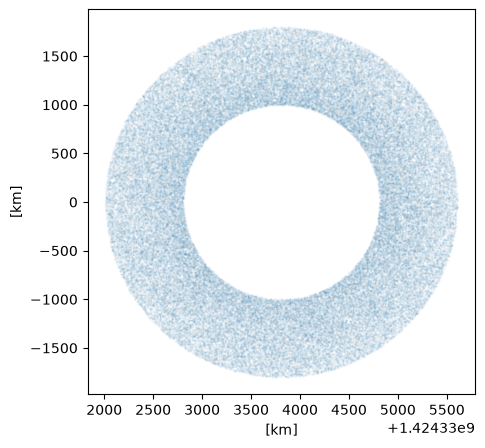

In [42]:
plt.figure(figsize=(5, 5))
scatter(ring.x, ring.y, s=1, marker='.', alpha=0.05)
plt.show()
plt.close('all')

### Test particle (not added to ParticleSet)

In [25]:
#ARTIFICAL COLLISION TEST
#Source: Adapted from Simon's collision example and the collision stopping conditions in AMUSE.
#Our circular debris orbits should remain stable. Therefore, we add ONE extra particle that will deliberately fall onto Iapetus.
#This is only a numerical test of collision detection,
impact_test = Particles(1)
impact_test.name = ['test'.casefold()]

# Give the test particle the same small gravitational mass as one of our debris tracers.

impact_test.mass = ring[0].mass
impact_test.radius = 0 | units.km

# Place it 900 km from Iapetus's center. Since Iapetus has a radius of 735 km, the particle starts 165 km above the surface.
impact_test[0].position = moon.position + ([1900, 0, 0] | units.km)

# Give it the same velocity as Iapetus. Its initial velocity relative to Iapetus is zero,
impact_test[0].velocity = moon.velocity

### Putting system together

In [43]:
#COMBINE ALL PARTICLES
#Source: AMUSE textbook particle-set methods.
#Ph4 needs to receive all the gravitating particles.

particles = a.copy()
particles.add_particles(ring)

# Add the artificial surface-collision particle.
# particles.add_particles(impact_test)

# '''
# Particle order in the combined set:
#     particles[0] = Sun
#     particles[1] = Saturn
#     particles[2] = Iapetus
#     particles[3:103] = 100 debris particles
#     particles[103] = artificial test particle
# '''

### Make ph4 and channels

In [44]:
# INITIALIZE PH4
# Convert physical SI units into the dimensionless N-body units used internally by the integrator

converter = nbody_system.nbody_to_si(saturn_mass, saturn_iapetus_distance)

# start the Ph4 gravitational solver
gravity = Ph4(converter)

# Accuracy/timestep control for Ph4. timestep of 0.01 is a dimensionless integrator parameter

# gravity.parameters.timestep_parameter = 0.01

# copied the particles into the gravitational solver
_ = gravity.particles.add_particles(particles)

In [9]:
# print(gravity.parameters)

In [45]:
#Ph4 maintains its own copy of the particle data. The channel lets us copy updated positions and velocities back to our Python particle set
channel = gravity.particles.new_channel_to(particles)

channels = {}
channels['to_gravity'] = particles.new_channel_to(gravity.particles)
channels['from_gravity'] = gravity.particles.new_channel_to(particles)

In [46]:
# ENABLE COLLISION DETECTION
#Source: Simon's second live-coding notebook.
#This uses Ph4's built-in collision stopping condition

collision_detection = gravity.stopping_conditions.collision_detection
collision_detection.enable()

In [47]:
#INITAL DIAGNOSTICS
#Source: Adapted from Chris's utils.py.
#We print the initial number of debris particles and their mean distance from Iapetus.

print(f'Ring tracers: {len(ring)}')
print(f'Initial ring mean radius: {r.mean()}')

Ring tracers: 100000
Initial ring mean radius: 1400.49994933 km


## Evolve (a.k.a. actually running the simulation)

In [198]:
# EVOLVE_DURATION = 10 | units.hour

# # Record the wall-clock starting time to measure how long the calculation takes on the computer
# start = time.perf_counter()

# #EVOLVE GRAVITY
# #We ask Ph4 to evolve for one hour. However, because collision detection is enabled,Ph4 can stop BEFORE one hour if particles collide.

# try:
#     gravity.evolve_model(EVOLVE_DURATION)
#     channel.copy()

#     if collision_detection.is_set():

#         #Obtain the two groups of particles involvedin the detected collision pairs.
#         first = collision_detection.particles(0)
#         second = collision_detection.particles(1)

#         #AMUSE gives every particle a unique key. We use these keys to verify that the collision involved Iapetus and artificial test particle.
#         moon_key = a[2].key
#         test_key = impact_test[0].key

#         # Check both possible orders because Iapetus could appear in either collision group.
#         expected = any((p.key == moon_key and q.key == test_key) or (p.key == test_key and q.key == moon_key) for p, q in zip(first, second))

#         #model_time gives the actual simulation time when Ph4 stopped, not the requested end time.
#         print('Collision detected at:',gravity.model_time.in_(units.minute))
#         print('Iapetus + artificial test tracer:',expected)

#         if not expected:
#             print('WARNING: collision involved a different particle pair')

#     else:
#         print(f'WARNING: collision detector did not trigger in {EVOLVE_DURATION}')


#     #CHECK DEBRIS RING STABILITY
#     #source: Adapted from orbital_radii() in Chris's utils.py
#     #using r = sqrt(dx^2 + dy^2 + dz^2) using relative positions
#     moon_now = particles[2]

#     # Select only the 100 original debris particles, excluding the artificial collision test particle.
#     debris_now = particles[3:3 + N]

#     #calculating the length of each resulting 3D vector.
#     radii = (debris_now.position - moon_now.position).lengths().value_in(units.km)

#     #the mean, minimum and maximum distances: These should remain approximately constant because the original debris particles started in nearly circular orbits.
#     print(f'Ring mean r = {radii.mean():.2f} km | 'f'min = {radii.min():.2f} km | 'f'max = {radii.max():.2f} km')
#     print(f'Elapsed wall time: 'f'{time.perf_counter() - start:.2f} s')

# finally:
#     #shut down the Ph4 worker
#     gravity.stop()


In [ ]:
EVOLVE_DURATION = 100 | units.hour

# Record the wall-clock starting time to measure how long the calculation takes on the computer
start = time.perf_counter()

#EVOLVE GRAVITY
#We ask Ph4 to evolve for one hour. However, because collision detection is enabled,Ph4 can stop BEFORE one hour if particles collide.
# fig, ax = plt.subplots(figsize=(5, 5))
particlesets = []
times = []
# artists = []
simulation_time = 0 | units.hour
dt = 1.0 | units.hour
while simulation_time < EVOLVE_DURATION:
    simulation_time += dt
    gravity.evolve_model(simulation_time)
    channel.copy()

    if collision_detection.is_set():
        # print(f'Time is {simulation_time}')

        #Obtain the two groups of particles involvedin the detected collision pairs.
        first = collision_detection.particles(0)
        second = collision_detection.particles(1)

        #AMUSE gives every particle a unique key. We use these keys to verify that the collision involved Iapetus and artificial test particle.
        moon_key = a[2].key
        test_key = impact_test[0].key

        # Check both possible orders because Iapetus could appear in either collision group.
        expected = any((p.key == moon_key and q.key == test_key) or (p.key == test_key and q.key == moon_key) for p, q in zip(first, second))

        # #model_time gives the actual simulation time when Ph4 stopped, not the requested end time.
        # print('Collision detected at:', gravity.model_time.in_(units.minute))
        # print('Iapetus + artificial test tracer:', expected)

        # if not expected:
        #     print('WARNING: collision involved a different particle pair')

    # else:
    #     print(f'WARNING: collision detector did not trigger in {EVOLVE_DURATION}')

    # Plotting
    particlesets.append(particles.copy())
    times.append(simulation_time)

    # art_list = animate_particles(particles)
    # artists += art_list

    # artists.append([ax_scatter(particles.x, particles.y, ax)])

#shut down the Ph4 worker
gravity.stop()

## Animation

In [ ]:
def animate_particles(particles, t=None):
    iap_x, iap_y = particles[2].x, particles[2].y
    # scatter(particles[0].x, particles[0].y, label='Sun')
    # scatter(particles[1].x, particles[1].y, label='Saturn')
    sca_iape = patches.Circle(
        (0, 0),
        radius=particles[2].radius.value_in(units.km),
        facecolor='r', linewidth=0, alpha=0.5
    )
    plt.gca().add_patch(sca_iape)
    sca_debr = scatter(
        particles[3:-1].x - iap_x, particles[3:-1].y - iap_y,
        label='Debris', c='b',
        s=1, marker='.', alpha=0.05
    )
    # sca_test = scatter(
    #     particles[-1].x - iap_x, particles[-1].y - iap_y,
    #     label='Test particle', c='g'
    # )
    ti_artist = plt.text(-20, 150, f'{t.value_in(units.hour):.2f} hr')
    lgd = plt.legend(bbox_to_anchor=[1.5, 0.6])
    return [
        sca_iape, sca_debr, 
        # sca_test,
        ti_artist, lgd
    ]

In [ ]:
# def ax_scatter(x, y, ax, **kwargs):
#     args = UnitlessArgs.strip(x, y)
#     result = ax.scatter(*UnitlessArgs.stripped_args, **kwargs)
#     ax.set_xlabel(UnitlessArgs.x_label())
#     ax.set_ylabel(UnitlessArgs.y_label())
#     return result

In [ ]:
# def func_ani(particles, t=None):
#     iap_x, iap_y = particles[2].x, particles[2].y
#     # scatter(particles[0].x, particles[0].y, label='Sun')
#     # scatter(particles[1].x, particles[1].y, label='Saturn')
#     # sca_iape = scatter(
#     #     0 | units.km, 0 | units.km,
#     #     s=particles[2].radius.value_in(units.km), alpha=0.5,
#     #     label='Iapetus', c='r'
#     # )
#     # sca_debr = scatter(
#     #     particles[3:-1].x - iap_x, particles[3:-1].y - iap_y,
#     #     label='Debris', c='b'
#     # )
#     sca_test = scatter(
#         particles[-1].x - iap_x, particles[-1].y - iap_y,
#         label='Test particle', c='g'
#     )
#     # ax.set_title(t)
#     # fig.legend(bbox_to_anchor=[1.5, 0.6])
#     # return [sca_iape, sca_debr, sca_test]

#     return sca_test

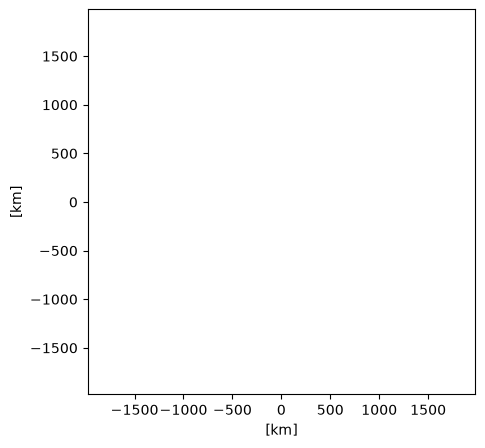

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
l = []
for p, t in zip(particlesets, times):
    l.append(animate_particles(p, t))

ani = animation.ArtistAnimation(fig=fig, artists=l, interval=100)

In [ ]:
ani.save('disk_100k_100h.mp4')
# ani.save('3.gif', writer='pillow')